<a href="https://colab.research.google.com/github/prajjaldhar/HousePricePrediction/blob/main/HousePrediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model  import LinearRegression

from sklearn.preprocessing import (StandardScaler,OneHotEncoder)

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

In [ ]:
df = pd.read_csv('./Housing.csv')
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [ ]:
df.shape

(545, 13)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [ ]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [ ]:
df.describe(include='object')

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
count,545,545,545,545,545,545,545
unique,2,2,2,2,2,2,3
top,yes,no,no,no,no,no,semi-furnished
freq,468,448,354,520,373,417,227


Check missing values and duplicates

In [ ]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [ ]:
df.duplicated().sum()

np.int64(0)

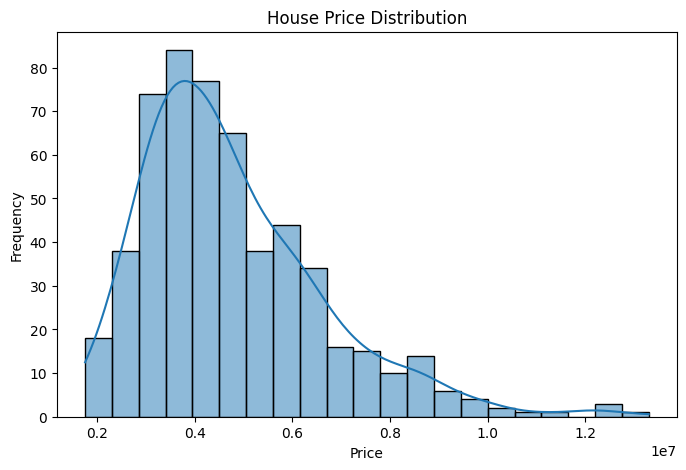

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['price'],kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

Area vs Price

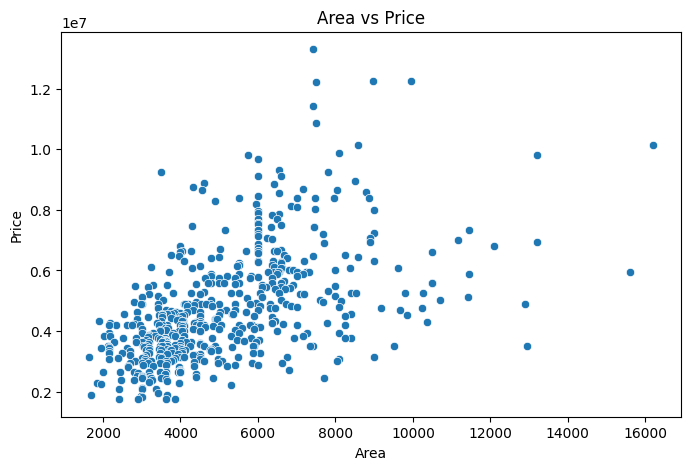

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(x='area',y='price',data=df)
plt.title("Area vs Price")
plt.xlabel("Area")
plt.ylabel("Price")
plt.show()

correlation heatmap

Text(0.5, 1.0, 'Correlation Heatmap')

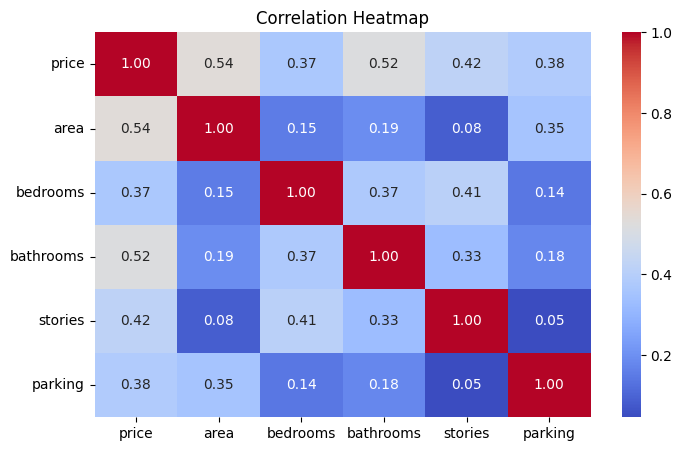

In [ ]:
plt.figure(figsize=(8,5))
sns.heatmap(
    df.select_dtypes(include=[np.number]).corr(),
    cmap="coolwarm",
    fmt=".2f",
    annot=True)
plt.title("Correlation Heatmap")

In [ ]:
X = df.drop('price',axis=1)
y = df['price']

In [ ]:
X

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...
540,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,2910,3,1,1,no,no,no,no,no,0,no,furnished


In [ ]:
y

,price
0,13300000
1,12250000
2,12250000
3,12215000
4,11410000
...,...
540,1820000
541,1767150
542,1750000
543,1750000


In [ ]:
X.shape

(545, 12)

In [ ]:
y.shape

(545,)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [ ]:
X_train.shape

(436, 12)

In [ ]:
X_test.shape

(109, 12)

Identifying the numerical datasets

In [ ]:
numeric_features = X.select_dtypes(include=["int64","float64"]).columns.tolist()
numeric_features

['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

categorical features are:

In [ ]:
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()
categorical_features

['mainroad',
 'guestroom',
 'basement',
 'hotwaterheating',
 'airconditioning',
 'prefarea',
 'furnishingstatus']

In [ ]:
X[["area","bedrooms"]]

,area,bedrooms
0,7420,4
1,8960,4
2,9960,3
3,7500,4
4,7420,4
...,...,...
540,3000,2
541,2400,3
542,3620,2
543,2910,3


In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(X_train[numeric_features])
scaled_data

array([[ 0.38416819,  0.05527092,  1.53917323,  2.58764353,  0.36795665],
       [ 0.9291807 ,  0.05527092,  1.53917323, -0.91249891,  2.70998729],
       [-0.60775457, -1.28351359, -0.5579503 , -0.91249891,  1.53897197],
       ...,
       [-0.29709744,  0.05527092,  1.53917323,  1.42092939,  0.36795665],
       [-0.5060189 , -1.28351359, -0.5579503 , -0.91249891, -0.80305867],
       [ 0.15707965,  0.05527092,  1.53917323,  2.58764353,  0.36795665]],
      shape=(436, 5))

Categorical Data set:

In [ ]:
X_train[categorical_features]

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea,furnishingstatus
46,yes,no,no,no,yes,no,furnished
93,yes,no,yes,no,yes,no,semi-furnished
335,yes,no,yes,no,yes,no,furnished
412,yes,no,yes,no,no,yes,unfurnished
471,yes,no,no,no,no,no,unfurnished
...,...,...,...,...,...,...,...
71,yes,no,no,no,yes,no,unfurnished
106,yes,no,yes,no,yes,yes,semi-furnished
270,yes,no,no,yes,no,no,furnished
435,yes,no,no,no,no,no,unfurnished


In [ ]:
emcoder = OneHotEncoder(handle_unknown="ignore",drop="first")
encoder_data = emcoder.fit_transform(X_train[categorical_features])
encoder_data.toarray()

array([[1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 1., ..., 0., 1., 0.],
       [1., 0., 1., ..., 0., 0., 0.],
       ...,
       [1., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 1.],
       [1., 1., 0., ..., 0., 1., 0.]], shape=(436, 8))

Instead of transforming numerical and categorical columns separetly everytime, we can automate the process using ColumnTransformer

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric",StandardScaler(),numeric_features),
        ("categorical",OneHotEncoder(handle_unknown="ignore",drop="first"),categorical_features)
    ]
)
preprocessor

ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['area', 'bedrooms', 'bathrooms', 'stories',
                                  'parking']),
                                ('categorical',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['mainroad', 'guestroom', 'basement',
                                  'hotwaterheating', 'airconditioning',
                                  'prefarea', 'furnishingstatus'])])

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("regressor",LinearRegression())
    ]
)
model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

In [ ]:
model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['area', 'bedrooms',
                                                   'bathrooms', 'stories',
                                                   'parking']),
                                                 ('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['mainroad', 'guestroom',
                                                   'basement',
                                                   'hotwaterheating',
                                                   'airconditioning',
                                                   'prefarea',
                                                   'furnishingstatus'])])),
                ('regressor', LinearRegression())])

In [ ]:
y_pred = model.predict(X_test)
y_pred[:10]

array([5164653.90033967, 7224722.29802166, 3109863.24240338,
       4612075.3272256 , 3294646.25725956, 3532275.09556558,
       5611774.56836474, 6368145.98732718, 2722856.95689986,
       2629405.61585783])

In [ ]:
comparison  = pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
comparison.head()

,Actual,Predicted
316,4060000,5.164654e+06
77,6650000,7.224722e+06
360,3710000,3.109863e+06
90,6440000,4.612075e+06
493,2800000,3.294646e+06


In [ ]:
mae = mean_absolute_error(y_test,y_pred)
mae

970043.403920164

In [ ]:
mse = mean_squared_error(y_test,y_pred)
mse

1754318687330.6667

In [ ]:
r2 = r2_score(y_test,y_pred)
r2

0.6529242642153178

In [ ]:
rmse = np.sqrt(mse)
rmse

np.float64(1324506.9600914398)

In [ ]:
evaluation = pd.DataFrame(
    {
        "Model":["Linear Regression"],
        "MAE":[mae],
        "MSE":[mse],
        "RMSE":[rmse],
        "R2 Score":[r2]
    }
)
evaluation

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,970043.40392,1.754319e+12,1.324507e+06,0.652924


In [ ]:
new_house = pd.DataFrame([{
    "area":6500,
    "bedrooms":3,
    "bathrooms":2,
    "mainroad":"yes",
    "guestroom":"no",
    "stories":2,
    "basement":"no",
    "hotwaterheating":"yes",
    "airconditioning":"yes",
    "parking":"2",
    "prefarea":"yes",
    "furnishingstatus":"furnished"
}])
predicted_price = model.predict(new_house)
predicted_price

array([7951579.41492879])